# Codveda ML Internship - Level 1
## Task 1: Data Preprocessing + Task 2: Linear Regression
Dataset: Kaggle House Prices (`train.csv`)

### 0. Upload the dataset

In [11]:
from google.colab import files
uploaded = files.upload()

Saving train.csv to train (1).csv


### 1. Imports and loading

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

df = pd.read_csv("train.csv").drop(columns=["Id"])
print("Shape:", df.shape)
df.head()

Shape: (1460, 80)


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### 2. Inspect missing values

In [13]:
missing = df.isna().mean().sort_values(ascending=False)
print(missing[missing > 0].head(15))

PoolQC          0.995205
MiscFeature     0.963014
Alley           0.937671
Fence           0.807534
MasVnrType      0.597260
FireplaceQu     0.472603
LotFrontage     0.177397
GarageQual      0.055479
GarageType      0.055479
GarageFinish    0.055479
GarageCond      0.055479
GarageYrBlt     0.055479
BsmtExposure    0.026027
BsmtFinType2    0.026027
BsmtQual        0.025342
dtype: float64


### 3. Drop mostly-empty columns (>40% missing), split features/target

In [14]:
df = df.drop(columns=missing[missing > 0.40].index)
X = df.drop(columns=["SalePrice"])
y = df["SalePrice"]

### 4. Train/test split (BEFORE fitting any transformer, to avoid data leakage)

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

(1168, 73) (292, 73)


### 5. Preprocessing pipeline
Numeric: median imputation + standardization. Categorical: most-frequent imputation + one-hot encoding.

In [16]:
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns

numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols),
])

X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

print("Train after preprocessing:", X_train_p.shape)
print("Test after preprocessing: ", X_test_p.shape)
print("Any NaN left?", pd.isna(X_train_p).any())

Train after preprocessing: (1168, 264)
Test after preprocessing:  (292, 264)
Any NaN left? False


## Task 2: Linear Regression

### 6. Train the model

In [17]:
model = LinearRegression()
model.fit(X_train_p, y_train)

LinearRegression()

### 7. Evaluate (R-squared, MSE, RMSE)

In [18]:
pred = model.predict(X_test_p)
mse = mean_squared_error(y_test, pred)
print(f"R-squared: {r2_score(y_test, pred):.3f}")
print(f"MSE:       {mse:,.0f}")
print(f"RMSE:      {mse ** 0.5:,.0f}")

R-squared: 0.885
MSE:       880,907,816
RMSE:      29,680


### 8. Interpret the coefficients
Numeric features are standardized, so a coefficient = price change for a 1-standard-deviation increase in that feature, holding the others constant.

In [19]:
coefs = pd.Series(model.coef_, index=feature_names)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)
top

,0
cat__RoofMatl_ClyTile,-582918.376949
cat__Condition2_PosN,-196260.457580
cat__RoofMatl_Metal,131193.505598
cat__GarageQual_Ex,127785.882931
cat__GarageCond_Ex,-118919.460977
cat__RoofMatl_WdShngl,97249.809331
cat__RoofMatl_Roll,89774.593343
cat__RoofMatl_Tar&Grv,89734.968656
cat__RoofMatl_WdShake,88020.370896
cat__RoofMatl_CompShg,86945.129125


### 9. Plots

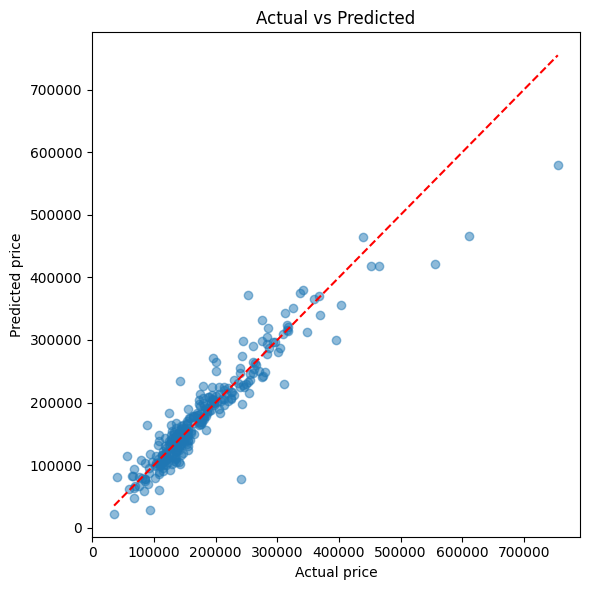

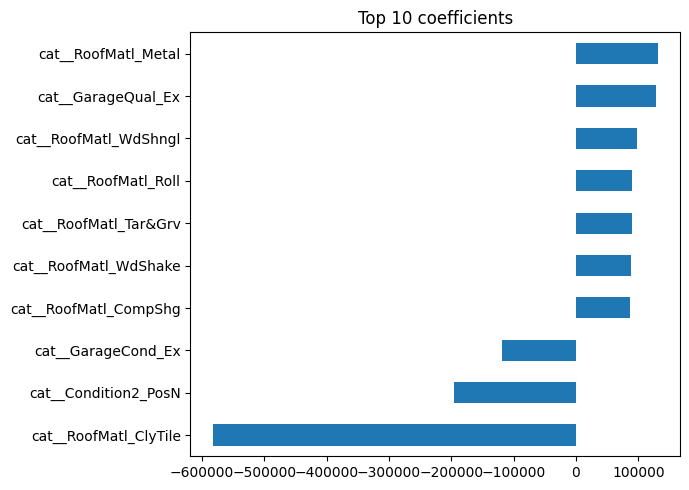

In [20]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual price"); plt.ylabel("Predicted price")
plt.title("Actual vs Predicted")
plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=150)
plt.show()

top.sort_values().plot(kind="barh", figsize=(7, 5), title="Top 10 coefficients")
plt.tight_layout()
plt.savefig("top_coefficients.png", dpi=150)
plt.show()